## Cài đặt


In [1]:
import os

# Nhập API key lấy từ Terminal PowerShell
api_key = input("Nhập Roboflow API key: ").strip()

if not api_key:
    raise ValueError("Bạn chưa nhập API key.")

print("Đã nhận API key:", bool(api_key))

Đã nhận API key: True


In [2]:
from roboflow import Roboflow

rf = Roboflow(api_key=api_key)
project = rf.workspace("thanh-tung-phan").project("biensoxe-o1lhe")
version = project.version(1)
dataset = version.download("yolov8")

print("Dataset:", dataset.location)
print("Data YAML:", f"{dataset.location}/data.yaml")

loading Roboflow workspace...
loading Roboflow project...
Dataset: c:\yolov8\alpr-vietnam-system\notebooks\BienSoXe-1
Data YAML: c:\yolov8\alpr-vietnam-system\notebooks\BienSoXe-1/data.yaml


## Chạy huấn luyện

In [3]:

from ultralytics import YOLO
from pathlib import Path
import torch

model = YOLO("yolov8n.pt")

# Tự chọn GPU nếu CUDA khả dụng, ngược lại chạy CPU
device = 0 if torch.cuda.is_available() else "cpu"

print("Thiết bị train:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

results = model.train(
    data=str(Path(dataset.location) / "data.yaml"),
    epochs=100,
    imgsz=640,
    batch=8,
    device=device,
    workers=4,
    project="alpr_vn",
    name="yolov8n_bienso",
    
    patience=30,

)

print("Train xong!")
print("Weights:", Path("alpr_vn/yolov8n_bienso/weights/best.pt").resolve())


Thiết bị train: 0
GPU: NVIDIA GeForce GTX 1650
New https://pypi.org/project/ultralytics/8.4.177 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.174  Python-3.11.9 torch-2.7.1+cu118 CUDA:0 (NVIDIA GeForce GTX 1650, 4096MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\yolov8\alpr-vietnam-system\notebooks\BienSoXe-1\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.0

## Kiểm tra biểu đồ huấn luyện

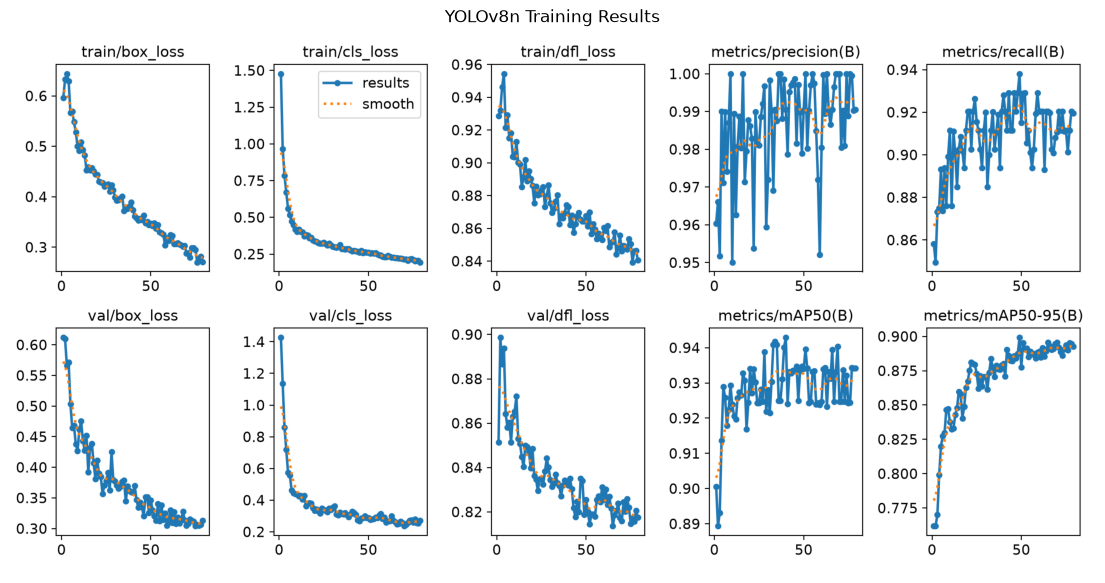

In [13]:

import matplotlib.pyplot as plt
import cv2
from pathlib import Path

chart_path = Path(
    r"D:\yolo\alpr-vietnam-system\runs\detect\alpr_vn\yolov8n_bienso-12\results.png"
)

if chart_path.exists():
    img = cv2.imread(str(chart_path))

    if img is not None:
        plt.figure(figsize=(14, 8))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        plt.title("YOLOv8n Training Results")
        plt.show()
    else:
        print("Không đọc được ảnh:", chart_path)
else:
    print("Chưa tìm thấy biểu đồ:", chart_path)


## Chạy huấn luyện phát hiện trên tập Test

In [16]:

from ultralytics import YOLO
from pathlib import Path

# Đường dẫn model đã train thành công
best_pt = Path(
    r"D:\yolo\alpr-vietnam-system\runs\detect\alpr_vn\yolov8n_bienso-12\weights\best.pt"
)

# Đường dẫn tập test
test_images = Path(dataset.location) / "test" / "images"

# Kiểm tra file
if not best_pt.exists():
    raise FileNotFoundError(f"Không tìm thấy model: {best_pt}")

if not test_images.exists():
    raise FileNotFoundError(f"Không tìm thấy tập test: {test_images}")

# Load model
model = YOLO(str(best_pt))
print("Đã tải model:", best_pt)

# Dự đoán trên tập test
test_results = model.predict(
    source=str(test_images),
    conf=0.5,
    iou=0.45,
    save=True,
    project=r"D:\yolo\alpr-vietnam-system\runs\predict",
    name="yolov8n_bienso_test",
    exist_ok=True
)

print("Đã chạy dự đoán trên tập test.")

if test_results:
    print("Kết quả lưu tại:", test_results[0].save_dir)


Đã tải model: D:\yolo\alpr-vietnam-system\runs\detect\alpr_vn\yolov8n_bienso-12\weights\best.pt

image 1/53 c:\yolov8\alpr-vietnam-system\notebooks\BienSoXe-1\test\images\BienSoXe-101-_jpg.rf.ae3c6c37092d2d2ab16ad9ba3686f7b6.jpg: 640x640 1 BienSoXe, 78.0ms
image 2/53 c:\yolov8\alpr-vietnam-system\notebooks\BienSoXe-1\test\images\BienSoXe-117-_jpg.rf.e152c179ebfc2cf05fa16c818ba1c846.jpg: 640x640 1 BienSoXe, 59.2ms
image 3/53 c:\yolov8\alpr-vietnam-system\notebooks\BienSoXe-1\test\images\BienSoXe-129-_jpg.rf.d76be6f76466fc42a55a79016d898390.jpg: 640x640 1 BienSoXe, 60.1ms
image 4/53 c:\yolov8\alpr-vietnam-system\notebooks\BienSoXe-1\test\images\BienSoXe-169-_jpg.rf.0305ea108eb659504ca08f6addf1cc11.jpg: 640x640 1 BienSoXe, 57.0ms
image 5/53 c:\yolov8\alpr-vietnam-system\notebooks\BienSoXe-1\test\images\BienSoXe-171-_jpg.rf.78df54af27a190b300fdbf333931f3bf.jpg: 640x640 1 BienSoXe, 57.6ms
image 6/53 c:\yolov8\alpr-vietnam-system\notebooks\BienSoXe-1\test\images\BienSoXe-172-_jpg.rf.f99c1809